# 01 - Looking at the genetic code

The genetic code turns 3 DNA letters (a codon) into 1 amino acid. There are 64 codons but only 20 amino acids + stop, so most amino acids have more than one codon.

In this notebook I look at what happens when one letter of a codon changes (a mutation).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from geneticcode import GENETIC_CODE, MUTATIONS, error_cost, load_properties

## The code table

In [2]:
for first in "TCAG":
    for third in "TCAG":
        row = ""
        for second in "TCAG":
            codon = first + second + third
            row += codon + " " + GENETIC_CODE[codon] + "    "
        print(row)
    print()

TTT F    TCT S    TAT Y    TGT C    
TTC F    TCC S    TAC Y    TGC C    
TTA L    TCA S    TAA *    TGA *    
TTG L    TCG S    TAG *    TGG W    

CTT L    CCT P    CAT H    CGT R    
CTC L    CCC P    CAC H    CGC R    
CTA L    CCA P    CAA Q    CGA R    
CTG L    CCG P    CAG Q    CGG R    

ATT I    ACT T    AAT N    AGT S    
ATC I    ACC T    AAC N    AGC S    
ATA I    ACA T    AAA K    AGA R    
ATG M    ACG T    AAG K    AGG R    

GTT V    GCT A    GAT D    GGT G    
GTC V    GCC A    GAC D    GGC G    
GTA V    GCA A    GAA E    GGA G    
GTG V    GCG A    GAG E    GGG G    



The 2nd letter seems to matter most: the whole `_T_` column (TTT, CTT, ATT, GTT...) is F, L, I, M, V, which are all oily (hydrophobic) amino acids.

## What does a mutation do?

Every codon can change in 9 ways (3 positions x 3 other letters), so 64 x 9 = 576 mutations. I sort each one into:
- **same**: still the same amino acid
- **different**: a different amino acid
- **stop**: becomes a stop codon

In [3]:
counts = {1: {"same": 0, "different": 0, "stop": 0},
          2: {"same": 0, "different": 0, "stop": 0},
          3: {"same": 0, "different": 0, "stop": 0}}

for old_codon, new_codon, position in MUTATIONS:
    old_aa = GENETIC_CODE[old_codon]
    new_aa = GENETIC_CODE[new_codon]
    if old_aa == "*":
        continue  # start from real amino acids only
    if new_aa == "*":
        counts[position]["stop"] += 1
    elif new_aa == old_aa:
        counts[position]["same"] += 1
    else:
        counts[position]["different"] += 1

table = pd.DataFrame(counts).T
table.index.name = "position"
percent = (table.div(table.sum(axis=1), axis=0) * 100).round(1)
percent

,same,different,stop
position,,,
1,4.4,90.7,4.9
2,0.0,96.2,3.8
3,68.9,27.3,3.8


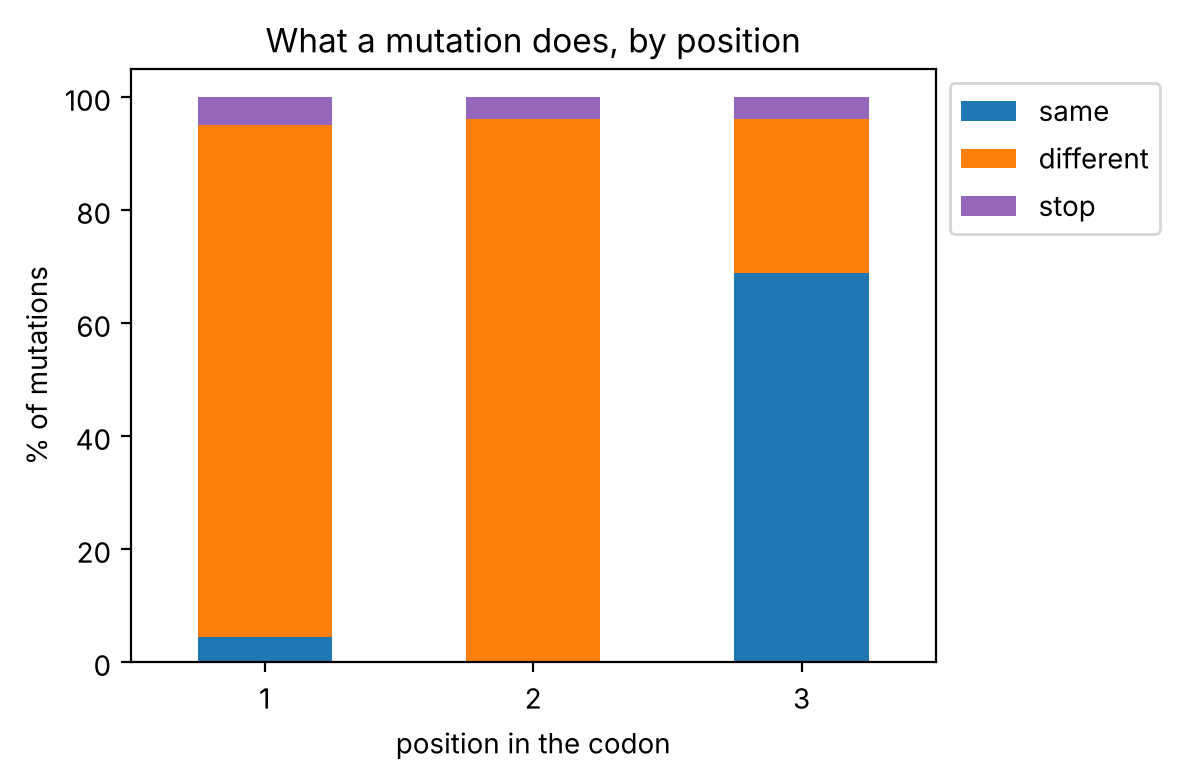

In [4]:
percent.plot(kind="bar", stacked=True, figsize=(6, 4), color=["tab:blue", "tab:orange", "tab:purple"])
plt.xlabel("position in the codon")
plt.ylabel("% of mutations")
plt.title("What a mutation does, by position")
plt.xticks(rotation=0)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig("figures/01_mutation_effects.png", dpi=120)
plt.show()

About 69% of mutations in the 3rd letter don't change anything. The 2nd letter never gives the same amino acid.

## How big is the change?

Changing to a *similar* amino acid is less harmful than changing to a very different one. To measure that I use **polar requirement**, a number from Woese et al. (1966) for how much an amino acid likes water. Low = oily, high = water-loving.

For each mutation I take (value before - value after)².

In [5]:
props = load_properties()
polar = props["polar_requirement"].to_dict()

squared = {1: [], 2: [], 3: []}
for old_codon, new_codon, position in MUTATIONS:
    old_aa = GENETIC_CODE[old_codon]
    new_aa = GENETIC_CODE[new_codon]
    if old_aa == "*" or new_aa == "*":
        continue
    squared[position].append((polar[old_aa] - polar[new_aa]) ** 2)

for position in [1, 2, 3]:
    print("position", position, ":", round(np.mean(squared[position]), 2))

position 1 : 4.88
position 2 : 10.56
position 3 : 0.14


So the 2nd letter causes the big changes, the 1st letter medium ones and the 3rd letter almost none.

Averaging over all mutations gives one score for the whole code (lower = mutations do less damage):

In [6]:
print("error cost of the real code:", round(error_cost(GENETIC_CODE, polar), 3))

error cost of the real code: 5.194


**5.194**, which is exactly the number in Haig & Hurst (1991), so my code matches the paper.

But is 5.194 good or bad? Notebook 02 compares it with random codes.